# Chapter 42: Platforms, Multi-Homing, Envelopment, and Digital Ecosystems

This notebook reruns four worked examples from the chapter: the competitive bottleneck for vendors, multi-homing restaurants, moving constraints in a retrofit ecosystem, and a cross-side fixed point on a developer platform. Every example is hypothetical, as in the book; a few extra input values are added for comparison. In the last example the book rounds n_D to 5.26 before multiplying; the exact values are used here.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def incremental_reach_value(unique, margin, fee, integration):
    """competitive-bottleneck / multi-homing: unique x margin - fee - integration.

    Book (ch042): 600(0.07) - 32 - 4 = 6; 150(0.07) - 32 - 4 = -25.50; 50(0.40) - 12 - 5 = 3.
    """
    return unique * margin - fee - integration


def ecosystem_adoption(potential, readiness):
    """complementary-assets-ecosystem-effect: A = potential x min(readiness shares).

    Book (ch042): 200 min{0.92, 0.55, 0.80, 0.70} = 110; with training 140; with finance too 150.
    Returns {"adoption": A, "binding": index of the smallest share}.
    """
    shares = list(readiness)
    low = min(shares)
    return {"adoption": potential * low, "binding": shares.index(low)}


def two_sided_fixed_point(a, b, prices):
    """two-sided-markets-switching-costs: fixed point of
    n_U = 100(4 + 0.01 n_D - p_U), n_D = 10(2 + 0.005 n_U - p_D), negatives replaced by 0.

    a = (scale_U, base_U, cross_U) = (100, 4, 0.01); b = (scale_D, base_D, cross_D) = (10, 2, 0.005);
    prices = (p_U, p_D). Book: p_U = 3, p_D = 2 gives n_U = 100/0.95 = 105.26, n_D = 5.2632
    (the book prints 5.26 and uses it for 5.26(30) = 157.80; exact 157.89).
    """
    sU, aU, kU = a
    sD, aD, kD = b
    pU, pD = prices
    iu, idd = sU * (aU - pU), sD * (aD - pD)
    mu, md = sU * kU, sD * kD
    det = 1 - mu * md
    nU = (iu + mu * idd) / det
    nD = (idd + md * iu) / det
    if nU < 0 or nD < 0:
        nU = nD = 0.0
        for _ in range(500):
            nU, nD = max(iu + mu * nD, 0.0), max(idd + md * nU, 0.0)
    return {"nU": nU, "nD": nD, "nU_direct": max(iu, 0.0)}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(incremental_reach_value=incremental_reach_value, ecosystem_adoption=ecosystem_adoption, two_sided_fixed_point=two_sided_fixed_point)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'competitive-bottleneck-in-two-sided-markets': {'commuters': 600,
                                                 'margin': 0.07,
                                                 'fee': 32,
                                                 'integration': 4,
                                                 'gross': 42,
                                                 'payoff': 6,
                                                 'vendors': 120,
                                                 'per_commuter': 8.4,
                                                 'overlap': 450,
                                                 'unique': 150,
                                                 'gross_overlap': 10.5,
                                                 'payoff_overlap': -25.5,
                                                 'max_fee': 38,
                                                 'max_fee_overlap': 6.5},
 'multi-homing-in-two-sided-markets': {'dA': 90,
                                       'dB': 50,
                                       'margin': 0.4,
                                       'listing': 12,
                                       'h': [1, 5, 9],
                                       'add_B_h5': 3,
                                       'add_B_h9': -1,
                                       'overlap': 35,
                                       'add_B_overlap_h5': -11,
                                       'add_B_overlap_h1': -7},
 'complementary-assets-ecosystem-effect': {'potential': 200,
                                           'readiness': (0.92, 0.55, 0.8, 0.7),
                                           'A': 110,
                                           'train_to': 0.75,
                                           'train_cost': 15000,
                                           'A_train': 140,
                                           'per_install': 900,
                                           'gain': 27000,
                                           'net': 12000,
                                           'finance_to': 0.85,
                                           'A_both': 150},
 'two-sided-markets-switching-costs': {'a': (100, 4, 0.01),
                                       'b': (10, 2, 0.005),
                                       'pU': 3,
                                       'pD': 2,
                                       'nU': 105.26,
                                       'nD_printed': 5.26,
                                       'dev_value': 30,
                                       'dev_total_printed_as': 157.8,
                                       'dev_total_exact_2dp': 157.89,
                                       'discount_cost': 105.26,
                                       'net_printed_as': 52.54,
                                       'net_exact_2dp': 52.63,
                                       'nD_exact_4dp': 5.2632},
 'constructed': {'competitive-bottleneck-in-two-sided-markets': {'overlap': [225],
                                                                 'fee': [6.5, 20]},
                 'complementary-assets-ecosystem-effect': {'finance_only': True},
                 'two-sided-markets-switching-costs': {'pU': [2], 'pD': [1.5]}}}


def bottleneck_picture(overlap=0, fee=32.0):
    b = BV["competitive-bottleneck-in-two-sided-markets"]
    m, h = b["margin"], b["integration"]
    unique = b["commuters"] - overlap
    gross = unique * m
    pay = industrial.incremental_reach_value(unique, m, fee, h)
    cap = industrial.incremental_reach_value(unique, m, 0, h)
    joins = pay >= 0
    verdict = "indifferent" if abs(pay) < 1e-9 else ("joins" if joins else "stays off")
    fig, ax = new_figure()
    bar_compare(ax, ["Value of new reach", "Fee plus integration"], [gross, fee + h], colors=["teal", "terracotta"],
                value_labels=[money(gross), money(fee + h)], ylabel="Dollars per vendor", xlabel="Adding South")
    ax.set_ylim(0, 50)
    label(ax, 0.5, 45, f"payoff {money(pay)}: {verdict}", col="ink", ha="center")
    metrics = {"New commuters reached": num(unique, 0), "Gross value": money(gross), "Payoff from adding South": money(pay),
               "Maximum fee": money(cap), "Vendor adds South": ("indifferent (payoff zero)" if verdict == "indifferent" else "yes" if joins else "no")}
    interp = (f"With {overlap} South commuters already on North, adding South reaches {unique} new commuters worth "
              f"{unique} x 0.07 = {num(gross)} dollars. The payoff is {num(gross)} - {num(fee)} - 4 = {num(pay)} dollars, so the "
              f"vendor {'is just indifferent about adding' if verdict == 'indifferent' else 'adds' if joins else 'does not add'} South. The most South can charge is {num(gross)} - 4 = "
              f"{money(cap)}.")
    steps = [f"Unique reach = 600 - {overlap} = {unique}",
             f"Gross value = {unique} x 0.07 = {num(gross)}",
             f"Payoff = {num(gross)} - {num(fee)} - 4 = {num(pay)}",
             f"Maximum fee = {num(gross)} - 4 = {num(cap)}"]
    alt = (f"Two bars: the value of {unique} new commuters, {money(gross)}, against the fee plus integration, "
           f"{money(fee + h)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def multihome_picture(h=5, overlap=0):
    b = BV["multi-homing-in-two-sided-markets"]
    m, L = b["margin"], b["listing"]
    unique = b["dB"] - overlap
    add = industrial.incremental_reach_value(unique, m, L, h)
    allowed = b["dB"] - (L + h) / m
    hs = [1, 5, 9]
    vals = [industrial.incremental_reach_value(unique, m, L, x) for x in hs]
    fig, ax = new_figure()
    bar_compare(ax, [f"h = {x}" for x in hs], vals,
                colors=["gold" if x == h else "light" for x in hs], value_labels=[money(v, 0) for v in vals],
                ylabel="Payoff from also listing on B ($)", xlabel="Integration cost per platform")
    ax.set_ylim(-18, 12)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    metrics = {"New diners from B": num(unique, 0), "Payoff from adding B": money(add, 0),
               "Multi-homes": "yes" if add > 0 else ("indifferent" if add == 0 else "no"),
               "Largest overlap that still pays": num(allowed, 1) if allowed >= 0 else "none (loses even with no overlap)"}
    interp = (f"After joining A, B adds {unique} new diners, so adding B pays {unique} x 0.40 - 12 - {h} = "
              f"{num(add, 0)} dollars. The restaurant {'multi-homes' if add > 0 else 'does not multi-home'}. At h = {h}, "
              f"adding B pays only while (50 - overlap)(0.40) >= {12 + h}, " + (f"that is overlap at most {num(allowed, 1)}." if allowed >= 0 else
                     "which fails even with no overlap, since 50 x 0.40 = 20 is below it."))
    steps = [f"New diners = 50 - {overlap} = {unique}",
             f"{unique} x 0.40 = {num(unique * m)}",
             f"{num(unique * m)} - 12 - {h} = {num(add)}",
             f"Overlap limit: 50 - {12 + h} / 0.40 = 50 - {num((L + h) / m, 1)} = {num(allowed, 1)}"]
    alt = f"Bars of the payoff from adding platform B at integration costs 1, 5 and 9 with {unique} new diners."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


NAMES = ["Equipment", "Installers", "Permits", "Finance"]


def ecosystem_picture(train="off", finance="off"):
    b = BV["complementary-assets-ecosystem-effect"]
    r = list(b["readiness"])
    if train == "on":
        r[1] = b["train_to"]
    if finance == "on":
        r[3] = b["finance_to"]
    res = industrial.ecosystem_adoption(b["potential"], r)
    A = res["adoption"]
    extra = A - b["A"]
    gain = extra * b["per_install"]
    cost = b["train_cost"] if train == "on" else 0
    fig, ax = new_figure()
    cols = ["terracotta" if i == res["binding"] else "teal" for i in range(4)]
    bar_compare(ax, NAMES, r, colors=cols, value_labels=[num(x) for x in r], ylabel="Readiness share",
                xlabel="Activity (red: binding)")
    ax.set_ylim(0, 1.15)
    metrics = {"Binding activity": NAMES[res["binding"]], "Completed adoption": num(A, 0),
               "Extra installations": num(extra, 0), "Contribution from extra installations": money(gain, 0),
               "Training cost": money(cost, 0), "Net of training cost": money(gain - cost, 0)}
    shares = ", ".join(num(x) for x in r)
    interp = (f"A = 200 min{{{shares}}} = 200 x {num(min(r))} = {num(A, 0)}, with {NAMES[res['binding']].lower()} "
              f"binding. That is {num(extra, 0)} more installations than 110, worth {num(extra, 0)}(900) = "
              f"{money(gain, 0)}; less training cost {money(cost, 0)} leaves {money(gain - cost, 0)}."
              + (" The finance agreement's own cost is not given in the book." if finance == "on" else ""))
    steps = [f"min{{{shares}}} = {num(min(r))} ({NAMES[res['binding']].lower()})",
             f"A = 200 x {num(min(r))} = {num(A, 0)}",
             f"Extra = {num(A, 0)} - 110 = {num(extra, 0)}",
             f"{num(extra, 0)} x 900 - {num(cost, 0)} = {num(gain - cost, 0)}"]
    alt = (f"Four readiness bars ({shares}); {NAMES[res['binding']].lower()} is the lowest and sets adoption at "
           f"{num(A, 0)} of 200 buildings.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def fixed_point_picture(p_u=3, p_d=2.0):
    b = BV["two-sided-markets-switching-costs"]
    res = industrial.two_sided_fixed_point(b["a"], b["b"], (p_u, p_d))
    nU, nD = res["nU"], res["nD"]
    iu, idd = 100 * (4 - p_u), 10 * (2 - p_d)
    dev = b["dev_value"] * nD
    cu = (4 - p_u) * nU
    cd = (2 - p_d) * nD
    net = dev - cu - cd
    xs = np.linspace(0, 240, 200)
    fig, ax = new_figure()
    ax.plot(xs, idd + 0.05 * xs, color=PALETTE["teal"], linewidth=2.2, label="developers: n_D = 10(2 + 0.005 n_U - p_D)")
    ys = np.linspace(0, 22, 200)
    ax.plot(iu + ys, ys, color=PALETTE["navy"], linewidth=2.2, label="users: n_U = 100(4 + 0.01 n_D - p_U)")
    mark(ax, nU, nD, f"({num(nU)}, {num(nD, 4)})", col="terracotta", dx=8 if nU < 80 else -8, dy=8, ha="left" if nU < 80 else "right")
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlim(0, 240)
    ax.set_ylim(0, 22)
    ax.set_xlabel("Users n_U")
    ax.set_ylabel("Developers n_D")
    metrics = {"Users n_U": num(nU), "Developers n_D": num(nD, 4), "Developer-side value": money(dev),
               "Cost of user discount": money(cu), "Cost of developer discount": money(cd),
               "Net cross-side gain": money(net)}
    k = 1 - 0.05
    interp = (f"At p_U = {num(p_u, 0)} and p_D = {num(p_d, 1)} the relations are n_U = {num(iu, 0)} + n_D and "
              f"n_D = {num(idd, 0)} + 0.05 n_U, so 0.95 n_U = {num(iu + idd, 0)} and n_U = {num(nU)}, "
              f"n_D = {num(nD, 4)}. Developers are worth 30 x {num(nD, 5)} = {money(dev)}; the discounts cost "
              f"{money(cu)} on users and {money(cd)} on developers, leaving {money(net)}."
              + (" The book rounds n_D to 5.26 before multiplying; the exact values are shown here."
                 if (p_u, p_d) == (3, 2) else ""))
    steps = [f"n_U = {num(iu, 0)} + n_D; n_D = {num(idd, 0)} + 0.05 n_U",
             f"n_U = ({num(iu, 0)} + {num(idd, 0)}) / {num(k)} = {num(nU, 5)}",
             f"n_D = {num(idd, 0)} + 0.05 x {num(nU, 5)} = {num(nD, 5)}",
             f"Developer value = 30 x {num(nD, 5)} = {num(dev)}",
             f"Discount costs = {num(4 - p_u, 0)} x {num(nU, 5)} + {num(2 - p_d, 1)} x {num(nD, 5)} = {num(cu + cd)}",
             f"Net = {num(dev)} - {num(cu + cd)} = {num(net)}"]
    alt = (f"User and developer response lines meet at {num(nU)} users and {num(nD, 4)} developers for prices "
           f"{num(p_u, 0)} and {num(p_d, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Competitive bottleneck: what access to exclusive commuters is worth

600 commuters per platform, 0.07 dollars per commuter reached, a 32-dollar fee and 4 dollars of integration.

$$600(0.07)=42 \qquad 42-32-4=6.$$

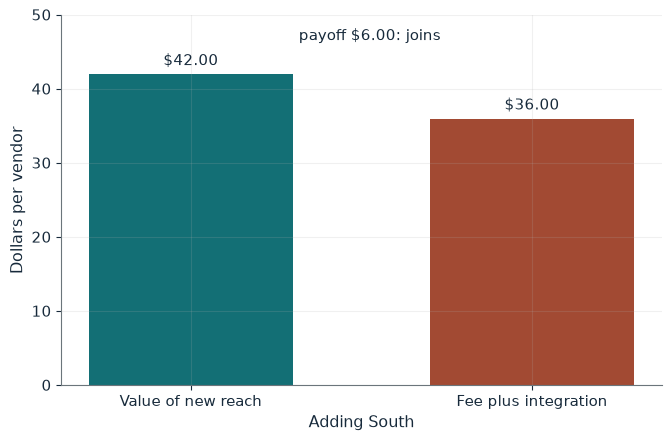

New commuters reached     600
Gross value               $42.00
Payoff from adding South  $6.00
Maximum fee               $38.00
Vendor adds South         yes

Worked steps:
  1. Unique reach = 600 - 0 = 600
  2. Gross value = 600 x 0.07 = 42.00
  3. Payoff = 42.00 - 32.00 - 4 = 6.00
  4. Maximum fee = 42.00 - 4 = 38.00

With 0 South commuters already on North, adding South reaches 600 new commuters worth 600 x 0.07 = 42.00 dollars. The payoff is 42.00 - 32.00 - 4 = 6.00 dollars, so the vendor adds South. The most South can charge is 42.00 - 4 = $38.00.


In [2]:
show(bottleneck_picture(overlap=0, fee=32.0))

Change one input, `overlap`, and hold the others at the book's values:

In [3]:
sweep(bottleneck_picture, 'overlap', [0, 225, 450], {'fee': 32.0}, ['New commuters reached', 'Payoff from adding South', 'Maximum fee'])

overlap | New commuters reached | Payoff from adding South | Maximum fee
0 | 600 | $6.00 | $38.00
225 | 375 | -$9.75 | $22.25
450 | 150 | -$25.50 | $6.50


Exclusive reach supports a fee up to 38 dollars. When 450 South commuters are also on North, only 150 are new, 150(0.07) = 10.50, and the maximum fee falls to 6.50.

## 2. Multi-homing: unique reach and duplication cost

B adds 50 diners at 0.40 each; a listing costs 12 and integration costs h.

$$50(0.40)-12-h=8-h.$$

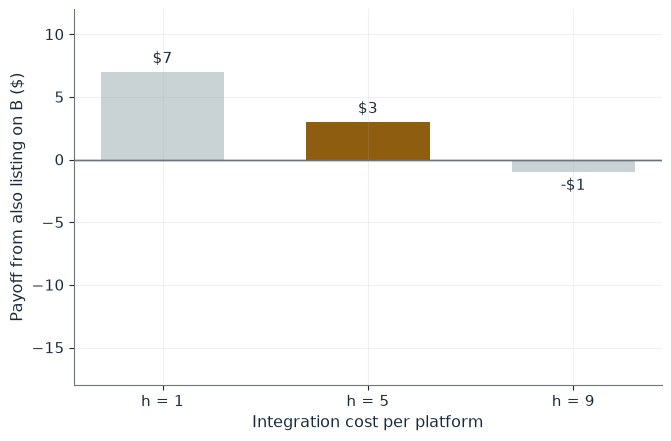

New diners from B                50
Payoff from adding B             $3
Multi-homes                      yes
Largest overlap that still pays  7.5

Worked steps:
  1. New diners = 50 - 0 = 50
  2. 50 x 0.40 = 20.00
  3. 20.00 - 12 - 5 = 3.00
  4. Overlap limit: 50 - 17 / 0.40 = 50 - 42.5 = 7.5

After joining A, B adds 50 new diners, so adding B pays 50 x 0.40 - 12 - 5 = 3 dollars. The restaurant multi-homes. At h = 5, adding B pays only while (50 - overlap)(0.40) >= 17, that is overlap at most 7.5.


In [4]:
show(multihome_picture(h=5, overlap=0))

Change one input, `h`, and hold the others at the book's values:

In [5]:
sweep(multihome_picture, 'h', [1, 5, 9], {'overlap': 35}, ['Payoff from adding B', 'Multi-homes'])

h | Payoff from adding B | Multi-homes
1 | -$7 | no
5 | -$11 | no
9 | -$15 | no


Without overlap, adding B pays 3 dollars at h = 5 and loses 1 at h = 9. With 35 diners overlapping, even h = 1 leaves 15(0.40) - 12 - 1 = -7.

## 3. Ecosystem effect: constraints move

200 buildings; readiness of equipment, installers, permits and finance.

$$A=200\min\{0.92,0.55,0.80,0.70\}=110.$$

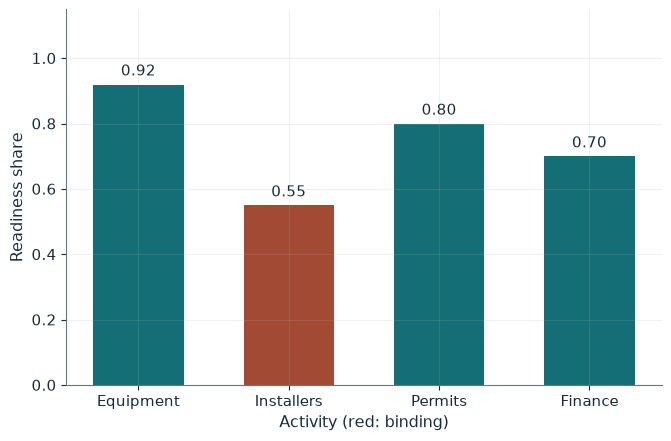

Binding activity                       Installers
Completed adoption                     110
Extra installations                    0
Contribution from extra installations  $0
Training cost                          $0
Net of training cost                   $0

Worked steps:
  1. min{0.92, 0.55, 0.80, 0.70} = 0.55 (installers)
  2. A = 200 x 0.55 = 110
  3. Extra = 110 - 110 = 0
  4. 0 x 900 - 0 = 0

A = 200 min{0.92, 0.55, 0.80, 0.70} = 200 x 0.55 = 110, with installers binding. That is 0 more installations than 110, worth 0(900) = $0; less training cost $0 leaves $0.


In [6]:
show(ecosystem_picture(train='off', finance='off'))

Change one input, `train`, and hold the others at the book's values:

In [7]:
sweep(ecosystem_picture, 'train', ['off', 'on'], {'finance': 'on'}, ['Binding activity', 'Completed adoption'])

train | Binding activity | Completed adoption
off | Installers | 110
on | Installers | 150


Training lifts adoption to 140 (net 27,000 - 15,000 = 12,000 dollars). Finance alone leaves 110, because installers still bind; with both, installers bind again at 150.

## 4. Two-sided markets: subsidize one side, gain on the other

$$n_U=100(4+0.01n_D-p_U),\qquad n_D=10(2+0.005n_U-p_D).$$

Each developer is worth 30 dollars; a user discount costs its size times the users served.

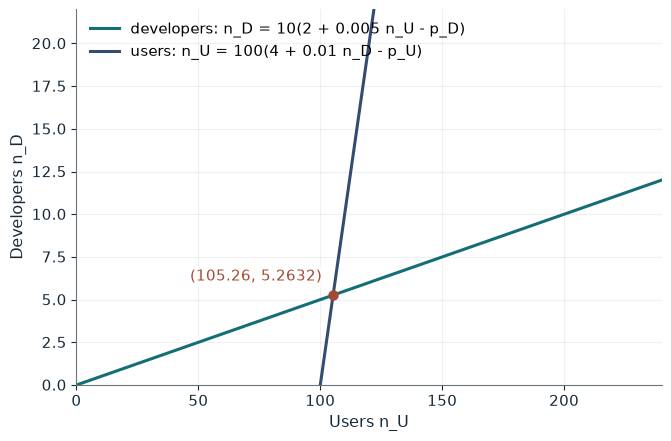

Users n_U                   105.26
Developers n_D              5.2632
Developer-side value        $157.89
Cost of user discount       $105.26
Cost of developer discount  $0.00
Net cross-side gain         $52.63

Worked steps:
  1. n_U = 100 + n_D; n_D = 0 + 0.05 n_U
  2. n_U = (100 + 0) / 0.95 = 105.26316
  3. n_D = 0 + 0.05 x 105.26316 = 5.26316
  4. Developer value = 30 x 5.26316 = 157.89
  5. Discount costs = 1 x 105.26316 + 0.0 x 5.26316 = 105.26
  6. Net = 157.89 - 105.26 = 52.63

At p_U = 3 and p_D = 2.0 the relations are n_U = 100 + n_D and n_D = 0 + 0.05 n_U, so 0.95 n_U = 100 and n_U = 105.26, n_D = 5.2632. Developers are worth 30 x 5.26316 = $157.89; the discounts cost $105.26 on users and $0.00 on developers, leaving $52.63. The book rounds n_D to 5.26 before multiplying; the exact values are shown here.


In [8]:
show(fixed_point_picture(p_u=3, p_d=2.0))

Change one input, `p_u`, and hold the others at the book's values:

In [9]:
sweep(fixed_point_picture, 'p_u', [2, 3, 4], {'p_d': 2.0}, ['Users n_U', 'Developers n_D', 'Net cross-side gain'])

p_u | Users n_U | Developers n_D | Net cross-side gain
2 | 210.53 | 10.5263 | -$105.26
3 | 105.26 | 5.2632 | $52.63
4 | 0.00 | 0.0000 | $0.00


At p_U = 3, n_U = 100/0.95 = 105.26 and n_D = 5.2632, so developers are worth 157.89 against a discount cost of 105.26: a net of 52.63. The book multiplies the rounded 5.26 and prints 157.80 and 52.54. A two-dollar discount loses 105.26.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

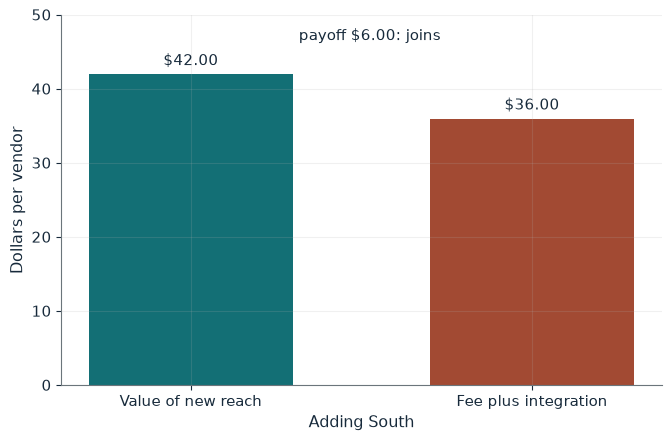

New commuters reached     600
Gross value               $42.00
Payoff from adding South  $6.00
Maximum fee               $38.00
Vendor adds South         yes

Worked steps:
  1. Unique reach = 600 - 0 = 600
  2. Gross value = 600 x 0.07 = 42.00
  3. Payoff = 42.00 - 32.00 - 4 = 6.00
  4. Maximum fee = 42.00 - 4 = 38.00

With 0 South commuters already on North, adding South reaches 600 new commuters worth 600 x 0.07 = 42.00 dollars. The payoff is 42.00 - 32.00 - 4 = 6.00 dollars, so the vendor adds South. The most South can charge is 42.00 - 4 = $38.00.


In [10]:
show(bottleneck_picture(overlap=0, fee=32.0))

## Practice

**1.** At overlap 225 and a fee of 20, does the vendor add South?

<details><summary>Answer</summary>

375(0.07) = 26.25, and 26.25 - 20 - 4 = 2.25 > 0, so yes.

</details>

**2.** At h = 1, how much overlap can the restaurant tolerate?

<details><summary>Answer</summary>

(50 - o)(0.40) - 13 >= 0 gives o <= 17.5, so at most 17 overlapping diners.

</details>

**3.** At p_U = 3 and p_D = 1.5, what are participation levels?

<details><summary>Answer</summary>

n_U = 100 + n_D and n_D = 5 + 0.05 n_U, so 0.95 n_U = 105, n_U = 110.53 and n_D = 10.53.

</details>